In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from pathlib import Path

In [9]:

# Cell 1: Read ZIP Dataset



# ZIP file path
zip_path = Path("../data/dataset.zip")

# Open ZIP file
dataset = zipfile.ZipFile(zip_path, "r")

# Get all file names
file_names = dataset.namelist()

# Display dataset information
print("Total Files:", len(file_names))

print("\nFirst 20 Files:")

for file in file_names[:20]:
    print(file)


Total Files: 2004

First 20 Files:
Kvasir-SEG/
Kvasir-SEG/kavsir_bboxes.json
Kvasir-SEG/images/
Kvasir-SEG/images/ck2bxiswtxuw80838qkisqjwz.jpg
Kvasir-SEG/images/ck2bxknhjvs1x0794iogrq49k.jpg
Kvasir-SEG/images/ck2bxlujamu330725szlc2jdu.jpg
Kvasir-SEG/images/ck2bxpfgxu2mk0748gsh7xelu.jpg
Kvasir-SEG/images/ck2bxqz3evvg20794iiyv5v2m.jpg
Kvasir-SEG/images/ck2bxskgxxzfv08386xkqtqdy.jpg
Kvasir-SEG/images/ck2bxw18mmz1k0725litqq2mc.jpg
Kvasir-SEG/images/ck2395w2mb4vu07480otsu6tw.jpg
Kvasir-SEG/images/ck2da7fwcjfis07218r1rvm95.jpg
Kvasir-SEG/images/cjyzjzssvd8pq0838f4nolj5l.jpg
Kvasir-SEG/images/cjyzk8qieoboa0848ogj51wwm.jpg
Kvasir-SEG/images/cju5hi52odyf90817prvcwg45.jpg
Kvasir-SEG/images/cju5hjxaae3i40850h5z2laf5.jpg
Kvasir-SEG/images/cju5hl8nee8a40755fm8qjj0o.jpg
Kvasir-SEG/images/cju5hqz50e7o90850e0prlpa0.jpg
Kvasir-SEG/images/cju5ht88gedbu0755xrcuddcx.jpg
Kvasir-SEG/images/cju5huurrecm70801y680y13m.jpg


In [10]:

# Cell 2: Identify Image Files

# Supported image extensions
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

# Get original image paths
image_paths = []

for file in file_names:

    # Check file extension
    if file.lower().endswith(image_extensions):

        # Exclude mask files
        if "mask" not in file.lower():

            image_paths.append(file)

# Display results
print("Total Original Images:", len(image_paths))

print("\nFirst 10 Images:")

for path in image_paths[:10]:
    print(path)


Total Original Images: 1000

First 10 Images:
Kvasir-SEG/images/ck2bxiswtxuw80838qkisqjwz.jpg
Kvasir-SEG/images/ck2bxknhjvs1x0794iogrq49k.jpg
Kvasir-SEG/images/ck2bxlujamu330725szlc2jdu.jpg
Kvasir-SEG/images/ck2bxpfgxu2mk0748gsh7xelu.jpg
Kvasir-SEG/images/ck2bxqz3evvg20794iiyv5v2m.jpg
Kvasir-SEG/images/ck2bxskgxxzfv08386xkqtqdy.jpg
Kvasir-SEG/images/ck2bxw18mmz1k0725litqq2mc.jpg
Kvasir-SEG/images/ck2395w2mb4vu07480otsu6tw.jpg
Kvasir-SEG/images/ck2da7fwcjfis07218r1rvm95.jpg
Kvasir-SEG/images/cjyzjzssvd8pq0838f4nolj5l.jpg


In [11]:

# Cell 3: Load Image from ZIP

def load_image_from_zip(dataset, image_path):

    # Read image from ZIP file
    image_bytes = dataset.read(image_path)

    # Convert bytes to NumPy array
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)

    # Decode image
    image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    return image


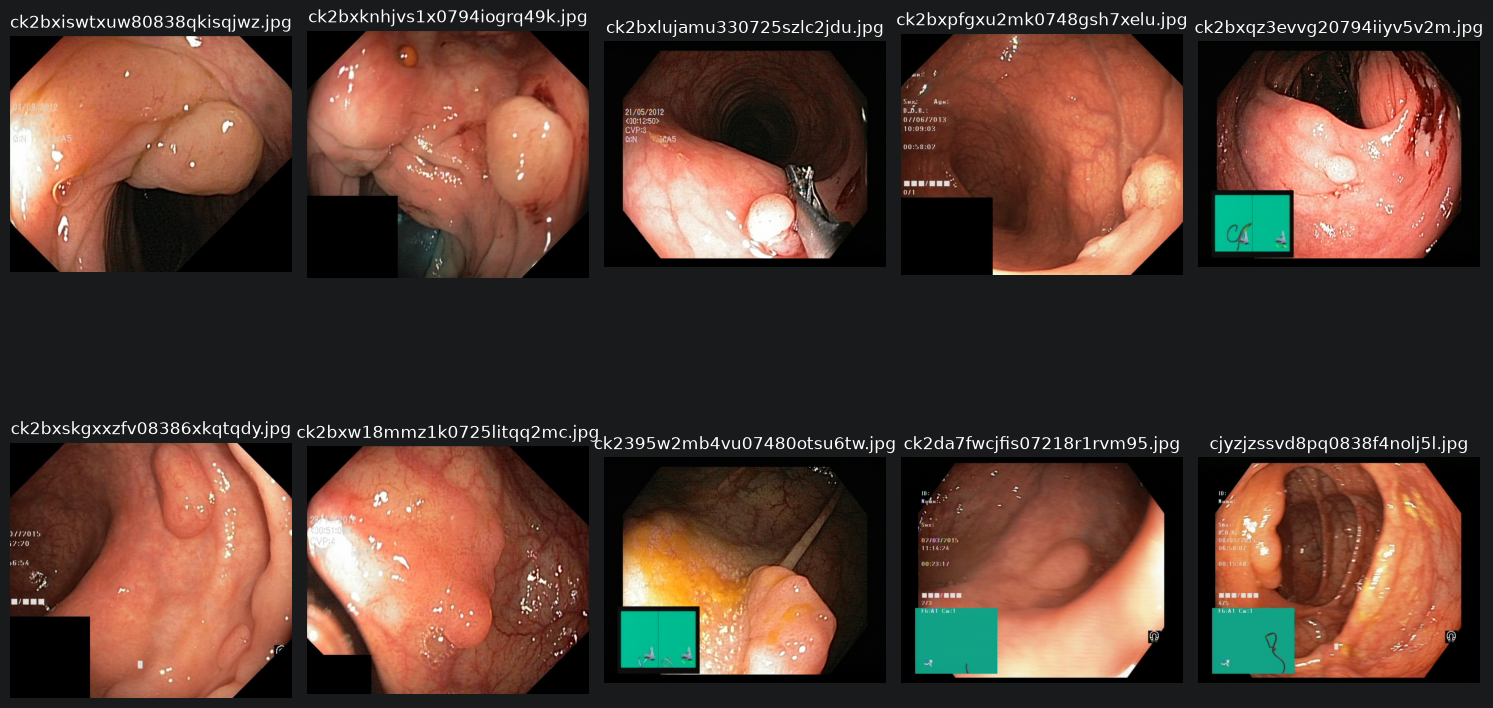

In [12]:
# Display 10 sample images

def display_sample_images(dataset, image_paths):

    plt.figure(figsize=(15, 10))

    for i in range(10):

        # Load image
        image = load_image_from_zip(dataset, image_paths[i])

        # Display image
        plt.subplot(2, 5, i + 1)
        plt.imshow(image)
        plt.title(Path(image_paths[i]).name)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Run function
display_sample_images(dataset, image_paths)

In [13]:
# Analyze image properties

def image_properties(dataset, image_paths):

    for path in image_paths[:10]:

        # Load image
        image = load_image_from_zip(dataset, path)

        # Get image information
        height, width, channels = image.shape

        print("Image:", Path(path).name)
        print("Size:", width, "x", height)
        print("Channels:", channels)
        print("Data Type:", image.dtype)
        print("Intensity Range:", image.min(), "-", image.max())
        print("-" * 40)


# Run function
image_properties(dataset, image_paths)

Image: ck2bxiswtxuw80838qkisqjwz.jpg
Size: 621 x 520
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
----------------------------------------
Image: ck2bxknhjvs1x0794iogrq49k.jpg
Size: 603 x 528
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
----------------------------------------
Image: ck2bxlujamu330725szlc2jdu.jpg
Size: 720 x 576
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
----------------------------------------
Image: ck2bxpfgxu2mk0748gsh7xelu.jpg
Size: 621 x 531
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
----------------------------------------
Image: ck2bxqz3evvg20794iiyv5v2m.jpg
Size: 720 x 576
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
----------------------------------------
Image: ck2bxskgxxzfv08386xkqtqdy.jpg
Size: 585 x 530
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
----------------------------------------
Image: ck2bxw18mmz1k0725litqq2mc.jpg
Size: 600 x 528
Channels: 3
Data Type: uint8
Intensity Range: 0 - 255
-----

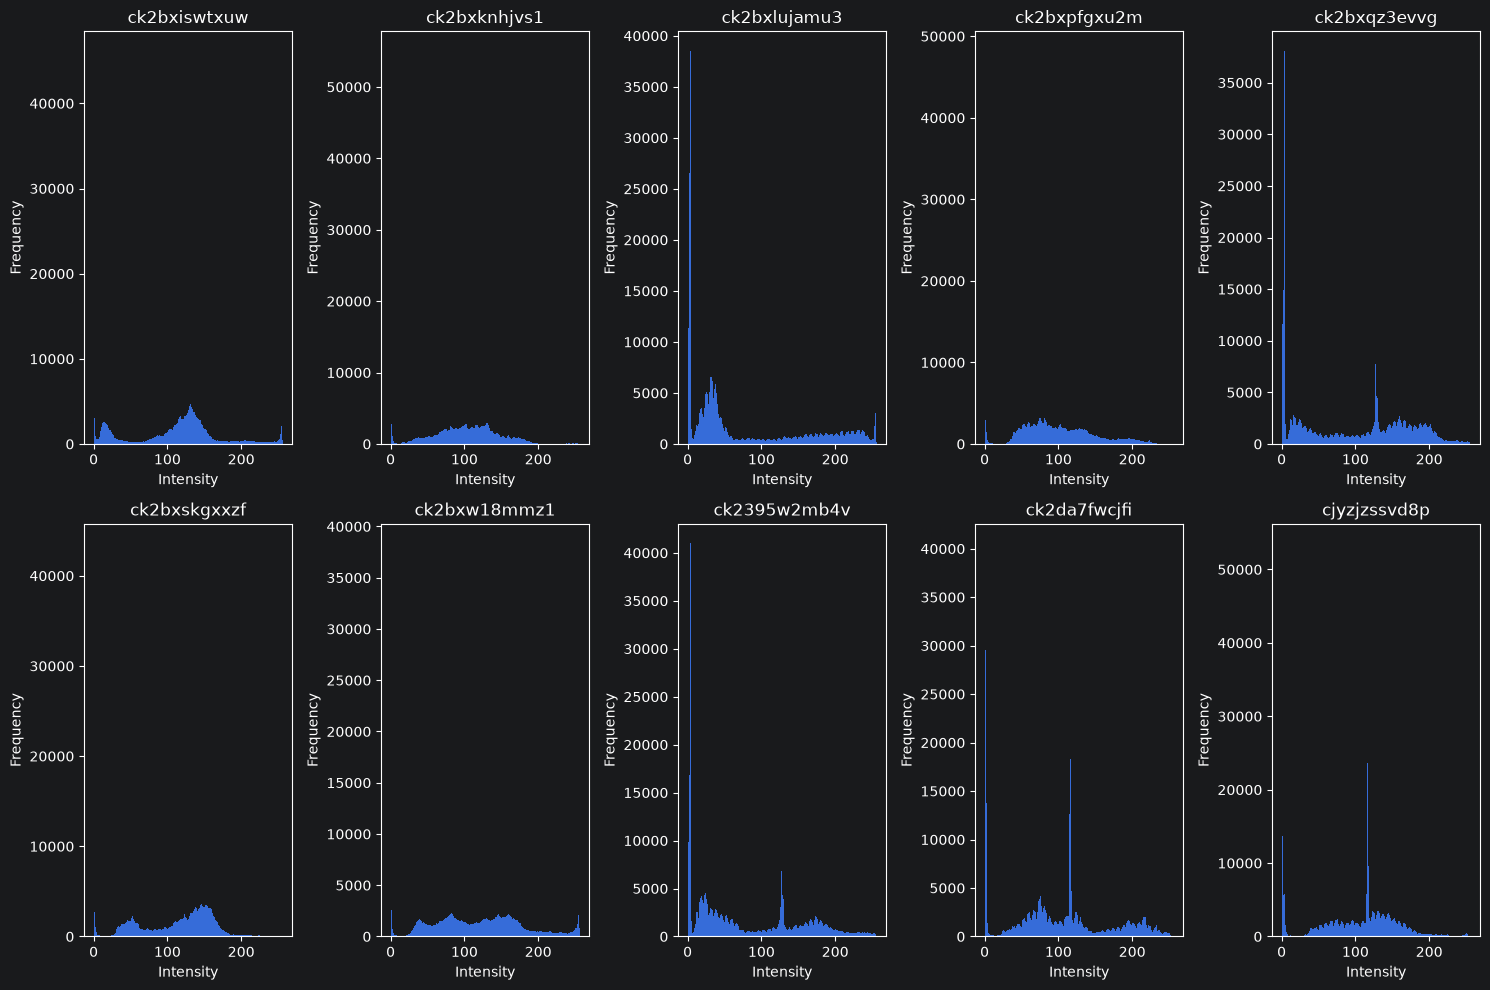

In [14]:
# Display histograms of 10 images

def display_histograms(dataset, image_paths):

    plt.figure(figsize=(15, 10))

    for i in range(10):

        # Load image
        image = load_image_from_zip(dataset, image_paths[i])

        # Convert RGB to Grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

        # Plot histogram
        plt.subplot(2, 5, i + 1)
        plt.hist(gray.ravel(), bins=256, range=(0, 256))
        plt.title(Path(image_paths[i]).name[:12])
        plt.xlabel("Intensity")
        plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()


# Run function
display_histograms(dataset, image_paths)

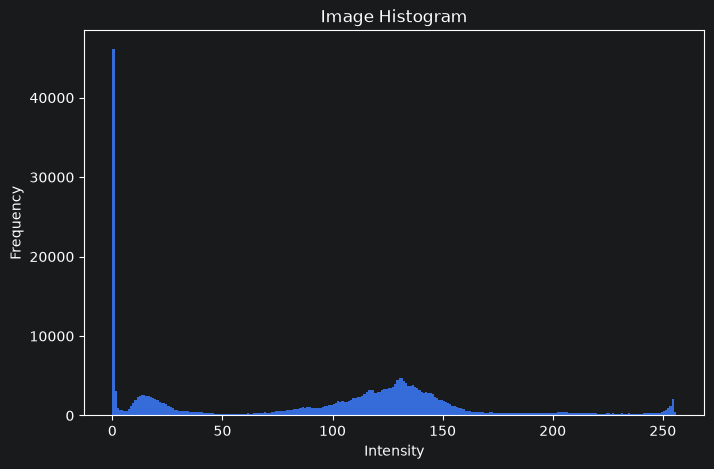

In [15]:
# Display histogram of one image

def display_histogram(dataset, image_paths):

    # Load image
    image = load_image_from_zip(dataset, image_paths[0])

    # Convert RGB to Grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Plot histogram
    plt.figure(figsize=(8, 5))
    plt.hist(gray.ravel(), bins=256, range=(0, 256))

    plt.title("Image Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")

    plt.show()


# Run function
display_histogram(dataset, image_paths)

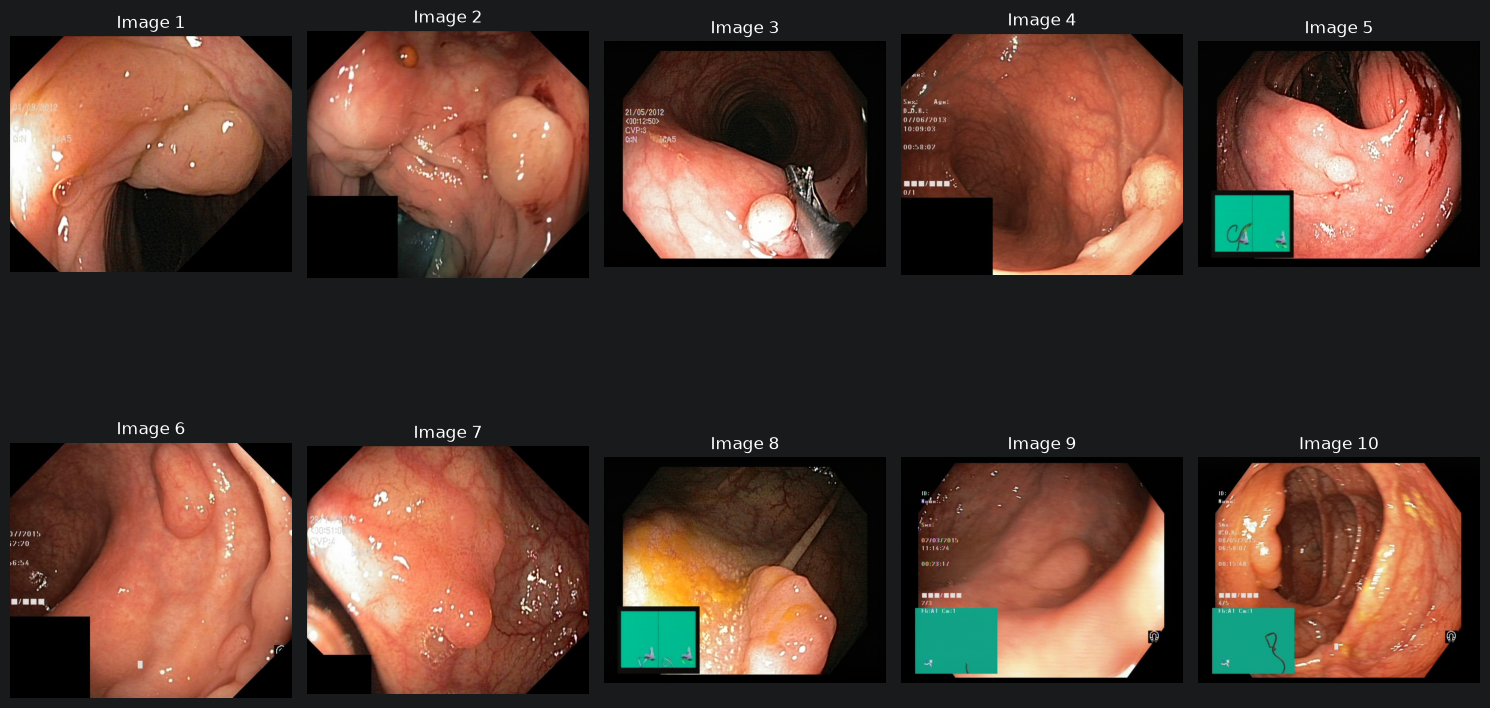

In [16]:
# Analyze visible noise in 10 images

def inspect_noise(dataset, image_paths):

    plt.figure(figsize=(15, 10))

    for i in range(10):

        # Load image
        image = load_image_from_zip(dataset, image_paths[i])

        # Display image
        plt.subplot(2, 5, i + 1)
        plt.imshow(image)
        plt.title("Image " + str(i + 1))
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Run function
inspect_noise(dataset, image_paths)

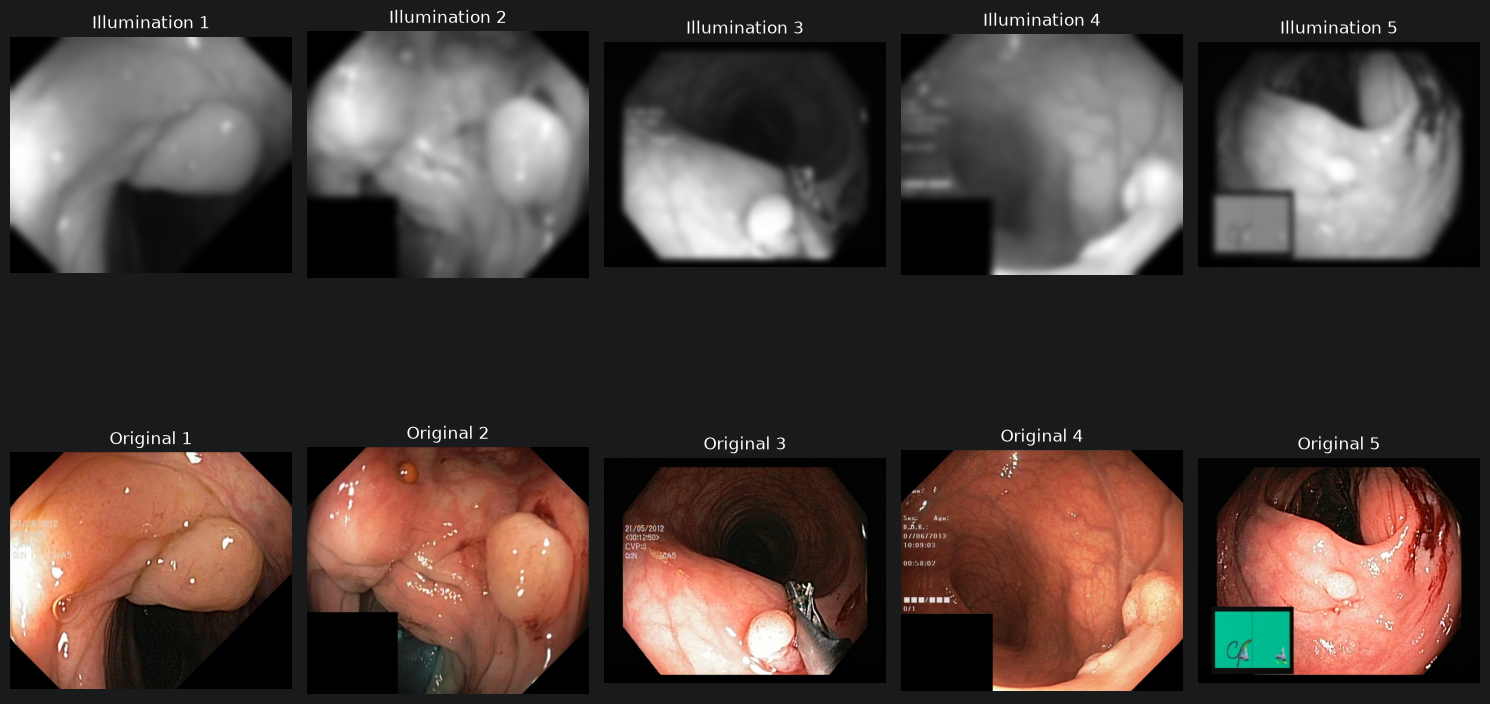

In [17]:
# Analyze image illumination

def analyze_illumination(dataset, image_paths):

    plt.figure(figsize=(15, 10))

    for i in range(5):

        # Load image
        image = load_image_from_zip(dataset, image_paths[i])

        # Convert to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

        # Estimate illumination using Gaussian Blur
        illumination = cv2.GaussianBlur(gray, (51, 51), 0)

        # Display illumination map
        plt.subplot(2, 5, i + 1)
        plt.imshow(illumination, cmap="gray")
        plt.title("Illumination " + str(i + 1))
        plt.axis("off")

        # Display original image
        plt.subplot(2, 5, i + 6)
        plt.imshow(image)
        plt.title("Original " + str(i + 1))
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Run function
analyze_illumination(dataset, image_paths)

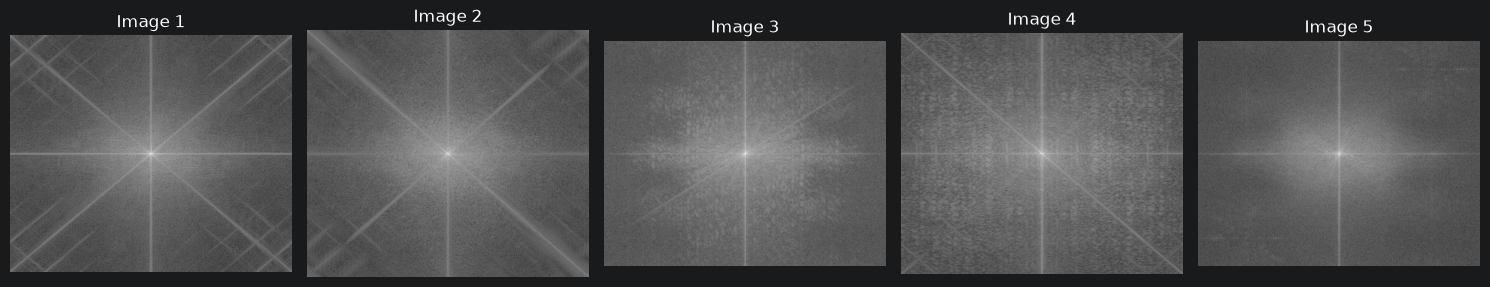

In [18]:
# Display Fourier Spectrum of 5 images

def display_fourier_spectrum(dataset, image_paths):

    plt.figure(figsize=(15, 8))

    for i in range(5):

        # Load image
        image = load_image_from_zip(dataset, image_paths[i])

        # Convert to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

        # Apply Fourier Transform
        fft = np.fft.fft2(gray)

        # Move low frequencies to the center
        fft_shift = np.fft.fftshift(fft)

        # Calculate log magnitude
        magnitude = np.log1p(np.abs(fft_shift))

        # Display spectrum
        plt.subplot(1, 5, i + 1)
        plt.imshow(magnitude, cmap="gray")
        plt.title("Image " + str(i + 1))
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Run function
display_fourier_spectrum(dataset, image_paths)

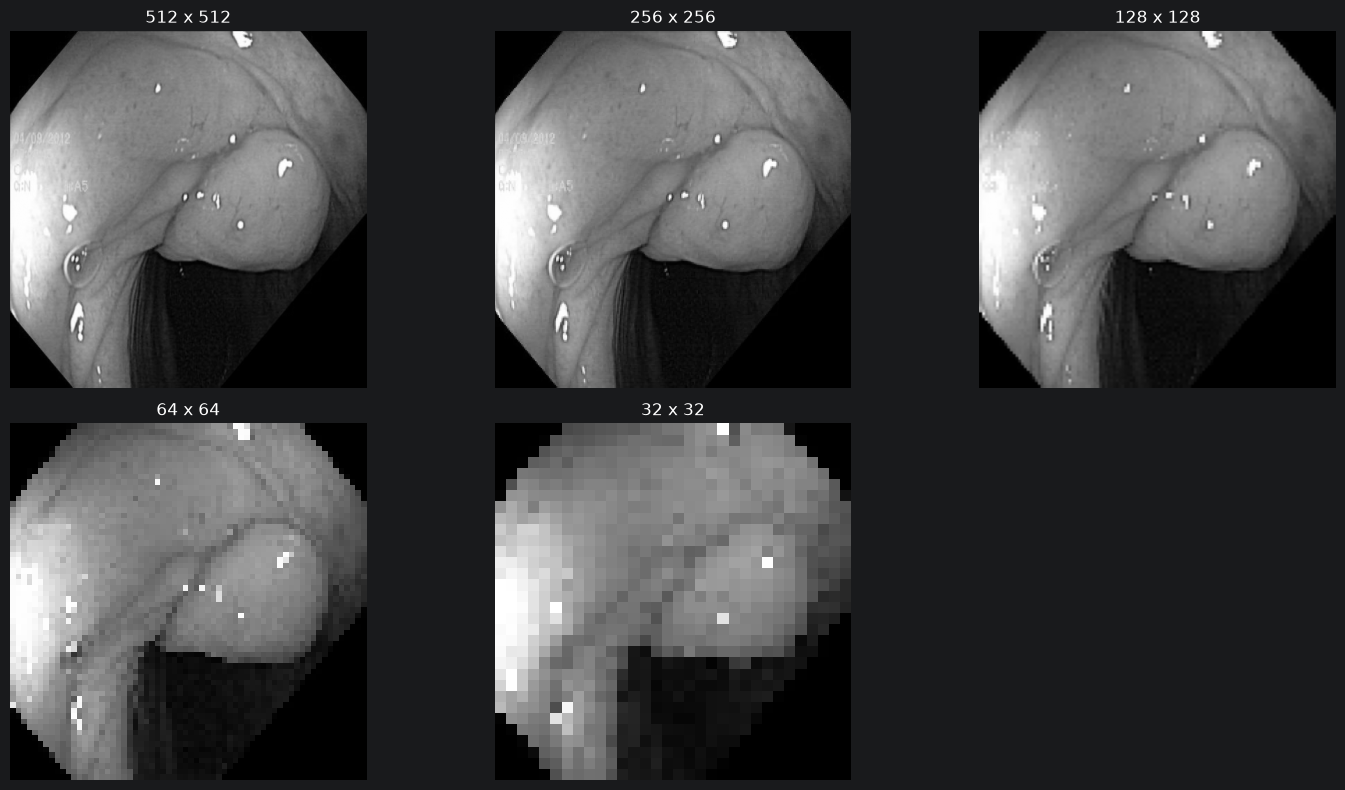

In [19]:
# Compare different spatial resolutions

def compare_resolutions(dataset, image_paths):

    # Load one image
    image = load_image_from_zip(dataset, image_paths[0])

    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Different resolutions
    sizes = [512, 256, 128, 64, 32]

    plt.figure(figsize=(15, 8))

    for i, size in enumerate(sizes):

        # Resize image
        resized = cv2.resize(gray, (size, size))

        # Display image
        plt.subplot(2, 3, i + 1)
        plt.imshow(resized, cmap="gray")
        plt.title(f"{size} x {size}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Run function
compare_resolutions(dataset, image_paths)

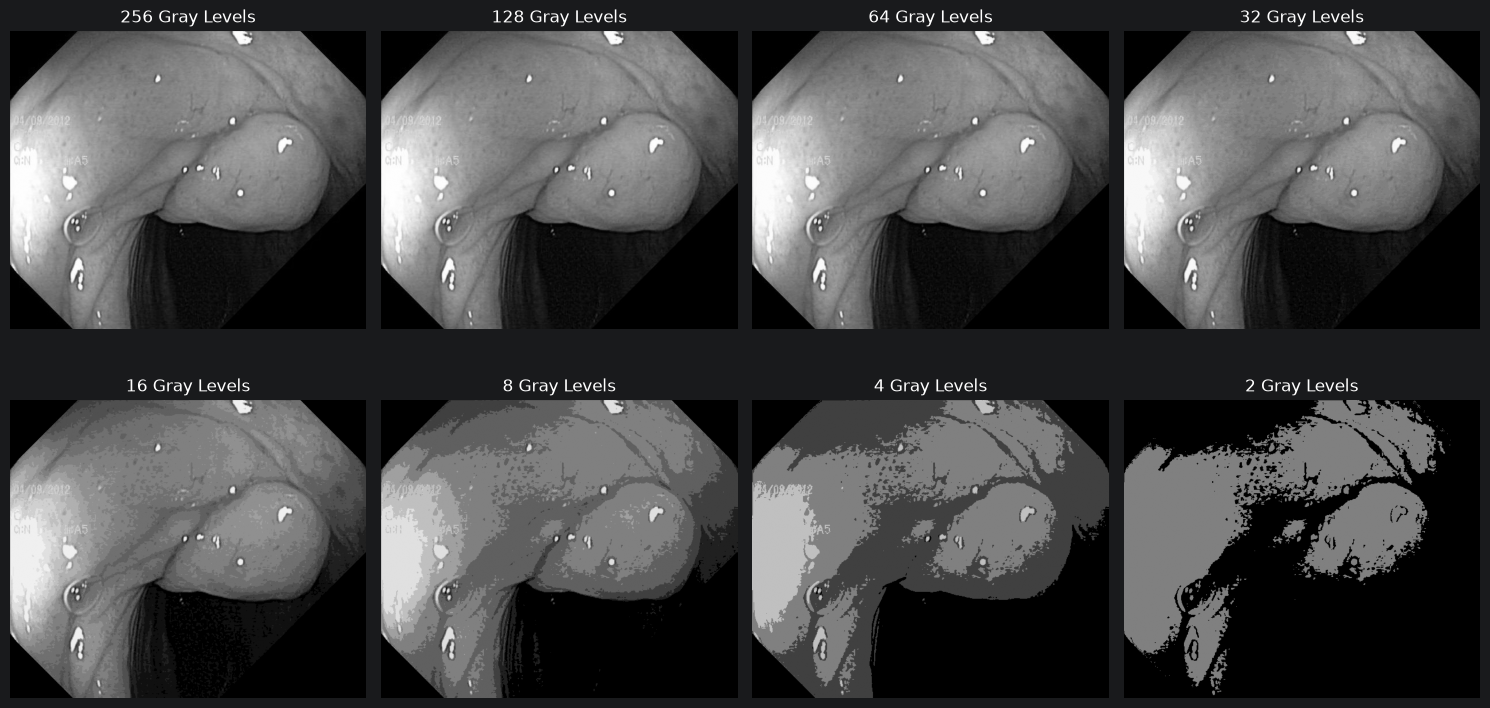

In [20]:
# Compare different gray levels

def compare_gray_levels(dataset, image_paths):

    # Load one image
    image = load_image_from_zip(dataset, image_paths[0])

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Different gray levels
    levels = [256, 128, 64, 32, 16, 8, 4, 2]

    plt.figure(figsize=(15, 8))

    for i, level in enumerate(levels):

        # Reduce gray levels
        reduced = (gray // (256 // level)) * (256 // level)

        # Display image
        plt.subplot(2, 4, i + 1)
        plt.imshow(reduced, cmap="gray", vmin=0, vmax=255)
        plt.title(f"{level} Gray Levels")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Run function
compare_gray_levels(dataset, image_paths)